# E4 — Esercitazione: pulire un dataset nuovo

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrealorenzon/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb)

## Come funziona un'esercitazione

Rispetto alle lezioni, qui hai **meno indicazioni**: per ogni passo trovi l'obiettivo e un **controllo** per verificare di esserci arrivato. Cosa cercare, sta a te (Google, Gemini, le dispense, i notebook delle lezioni).

- 👥 Si lavora in **gruppi da 3**, con tre ruoli che **ruotano a ogni incontro**: chi **scrive** (condivide lo schermo e scrive il codice nel suo notebook), chi **cerca** (Google, Gemini, dispense), chi **controlla** (il risultato ha senso? il numero torna?). Il codice sta tutto nel notebook di chi scrive: a fine lezione lo condivide con gli altri due (**Condividi** → chiunque abbia il link).
- Se il controllo non torna, **non andare avanti**: un errore all'inizio si porta dietro tutto il resto.
- 🆘 Bloccato **fuori dalla lezione**? In Colab: **Condividi** → aggiungi `andrelorenzon+sima2026@gmail.com` come **Editor**, poi scrivigli quale passo non torna.
- **File → Salva una copia in Drive** per non perdere il lavoro.

## Contesto

Un'azienda alimentare ti manda le sue esportazioni mensili del 2022 e del 2023, per paese e prodotto: `esportazioni.xlsx`. Vogliono sapere quanto hanno esportato in ogni paese. Prima, però, i dati vanno puliti: è il lavoro della L3, su un file che non hai mai visto.

Leggi la descrizione delle colonne in [`dati/README.md`](https://github.com/andrealorenzon/SIMA2026/blob/main/dati/README.md): ti servirà.

⏱️ **Prima di iniziare:** se non hai finito il task della L3, completalo ora (circa 20 minuti). Questa esercitazione usa le stesse tecniche su un file nuovo.

Sara Savy; Martina Pirozzi, Filippo Di Lorenzo

## Preparazione

Esegui questa cella così com'è: carica le librerie e il file delle esportazioni nella tabella `ex`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")

## Parte 1 — Pulizia

### 1. Conosci il file

Guarda le prime righe, le dimensioni e i tipi delle colonne. Scrivi qui sotto **tutti** i problemi che vedi, prima di correggere qualunque cosa.

In [7]:
display(ex.head())

print(ex.shape)
print(ex.dtypes)
print(ex.info())

,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,"€ 9.912,62"
1,feb 2023,Spagna,Olio EVO 1L,225,"€ 2.069,75"
2,dic 2022,Francia,Parmigiano 1kg,2357,"€ 49.332,02"
3,set 2023,DE,Pasta 500g,357,"€ 644,87"
4,nov 2022,Svizzera,Parmigiano 1kg,373,"€ 7.884,74"


(425, 5)
mese        object
paese       object
prodotto    object
quantita     int64
valore      object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   mese      425 non-null    object
 1   paese     425 non-null    object
 2   prodotto  425 non-null    object
 3   quantita  425 non-null    int64 
 4   valore    425 non-null    object
dtypes: int64(1), object(4)
memory usage: 16.7+ KB
None


*Risposta:* la colonna valore come dtype è object ma dovrebbe essere int.
- ...

### 2. Duplicati

Togli le righe duplicate.

✅ *Controllo:* 413 righe.

In [11]:
ex= ex.drop_duplicates()
print(ex.shape)


(413, 5)


### 3. Paesi

Fai in modo che ogni paese sia scritto in un solo modo, in italiano.

✅ *Controllo:* `ex["paese"].nunique()` dà 5.

In [19]:
print(ex['paese'].unique())
paesi_nuovo= {'Germany': 'Germania', 'Spagna ': 'Spagna', 'DE': 'Germania', 'germania': "Germania", 'FRANCIA': "Francia", 'U.S.A.': 'Stati Uniti', 'USA': "Stati Uniti", 'France': "Francia"}
ex['paese']= ex['paese'].replace(paesi_nuovo)
print(ex['paese'].unique())
print(ex['paese'].nunique())

['Germania' 'Spagna' 'Francia' 'Svizzera' 'Stati Uniti']
['Germania' 'Spagna' 'Francia' 'Svizzera' 'Stati Uniti']
5


### 4. Valore

Trasforma `valore` in numero (euro). Prima conta quante celle contengono solo un trattino `"-"`: dopo la conversione devono essere gli unici valori mancanti.

✅ *Controllo:* tanti valori mancanti quanti erano i trattini (9), e il primo valore della tabella è un numero con i decimali giusti.

In [28]:
conteggio_trattini= (ex['valore'].astype(str).str.strip()=='-').sum()
print(conteggio_trattini)
valore_pulito= ex['valore'].astype(str).str.replace('€','',regex=False).str.strip()
print(valore_pulito)
valore_pulito= valore_pulito.str.replace('.','',regex=False)
print(valore_pulito)
valore_pulito= valore_pulito.str.replace(',','.',regex=False)
print(valore_pulito)
ex['valore']= pd.to_numeric(valore_pulito,errors='coerce')
valori_mancanti= ex['valore'].isna().sum()
display(ex.head())
print(valori_mancanti)
print(ex['valore'])

0
0       9912.62
1       2069.75
2      49332.02
3        644.87
4       7884.74
         ...   
420      303.28
421      505.97
422      601.53
423     1405.79
424       941.2
Name: valore, Length: 413, dtype: object
0       991262
1       206975
2      4933202
3        64487
4       788474
        ...   
420      30328
421      50597
422      60153
423     140579
424       9412
Name: valore, Length: 413, dtype: object
0       991262
1       206975
2      4933202
3        64487
4       788474
        ...   
420      30328
421      50597
422      60153
423     140579
424       9412
Name: valore, Length: 413, dtype: object


,mese,paese,prodotto,quantita,valore
0,set 2022,Germania,Parmigiano 1kg,471,991262.0
1,feb 2023,Spagna,Olio EVO 1L,225,206975.0
2,dic 2022,Francia,Parmigiano 1kg,2357,4933202.0
3,set 2023,Germania,Pasta 500g,357,64487.0
4,nov 2022,Svizzera,Parmigiano 1kg,373,788474.0


9
0       991262.0
1       206975.0
2      4933202.0
3        64487.0
4       788474.0
         ...    
420      30328.0
421      50597.0
422      60153.0
423     140579.0
424       9412.0
Name: valore, Length: 413, dtype: float64


### 5. Mese

Trasforma `mese` (per esempio `"set 2022"`) in una vera data, il primo giorno del mese. Python non conosce le abbreviazioni dei mesi in italiano: il dizionario qui sotto può aiutarti.

✅ *Controllo:* 24 mesi diversi, nessuna data mancante, dal gennaio 2022 al dicembre 2023.

🔎 *Da cercare:* `pandas str split expand` · `pandas map dizionario` · `pandas to_datetime`

In [30]:
mesi = {"gen": 1, "feb": 2, "mar": 3, "apr": 4, "mag": 5, "giu": 6,
        "lug": 7, "ago": 8, "set": 9, "ott": 10, "nov": 11, "dic": 12}

# Split month abbreviation and year
split_mese = ex['mese'].str.split(' ', expand=True)
split_mese.columns = ['mese_nome', 'anno']

# Map Italian months to numbers
split_mese['mese_num'] = split_mese['mese_nome'].map(mesi)

# Create a datetime series using first day of each month
ex['mese'] = pd.to_datetime(split_mese['anno'].astype(str) + '-' + split_mese['mese_num'].astype(str) + '-01')

# Verification
print("Unique dates:", ex['mese'].nunique())
print("Missing values:", ex['mese'].isna().sum())
print("Min date:", ex['mese'].min())
print("Max date:", ex['mese'].max())


Unique dates: 24
Missing values: 0
Min date: 2022-01-01 00:00:00
Max date: 2023-12-01 00:00:00


### 6. Quantità negative

Quante righe hanno una quantità negativa? Sono errori da correggere? Leggi la descrizione delle colonne prima di decidere, e scrivi la tua decisione.

In [38]:
negativi= ex[ex['quantita']<0]

print(len(negativi))
display(negativi.head(11))


11


,mese,paese,prodotto,quantita,valore
8,2022-02-01,Francia,Pasta 500g,-41,-7094.0
28,2023-08-01,Stati Uniti,Passata 700g,-27,-6307.0
125,2023-06-01,Francia,Olio EVO 1L,-59,-51702.0
183,2022-12-01,Stati Uniti,Pasta 500g,-87,-16387.0
186,2023-04-01,Svizzera,Olio EVO 1L,-74,-69901.0
237,2023-11-01,Francia,Pasta 500g,-39,-6519.0
273,2022-07-01,Svizzera,Pasta 500g,-20,-3615.0
320,2022-09-01,Francia,Parmigiano 1kg,-134,-283248.0
385,2022-07-01,Svizzera,Olio EVO 1L,-23,-21488.0
401,2023-04-01,Spagna,Pasta 500g,-39,-7003.0


*Risposta:* non sono errori ma sono dei resi

## Parte 2 — Le domande dell'azienda

### 7. Per paese

Quanto ha esportato l'azienda in ogni paese nel 2023, in euro? Ordina dal paese più importante.

Per tenere solo il 2023: `data` ora è una vera data, e da una data si può estrarre l'anno (cerca `pandas dt year`).

✅ *Controllo:* 5 righe.

In [39]:
# Filtriamo i dati per tenere solo l'anno 2023
ex_2023 = ex[ex['mese'].dt.year == 2023]

# Raggruppiamo per paese, sommiamo il valore totale e ordiniamo in modo decrescente
esportazioni_paese_2023 = ex_2023.groupby('paese')['valore'].sum().sort_values(ascending=False).reset_index()

# Mostriamo il risultato
display(esportazioni_paese_2023)

,paese,valore
0,Francia,23201773.0
1,Svizzera,20811596.0
2,Spagna,18692089.0
3,Stati Uniti,15856186.0
4,Germania,14508102.0


### 8. Nel tempo

Disegna l'andamento del valore esportato totale, mese per mese. C'è un periodo dell'anno in cui si esporta di più?

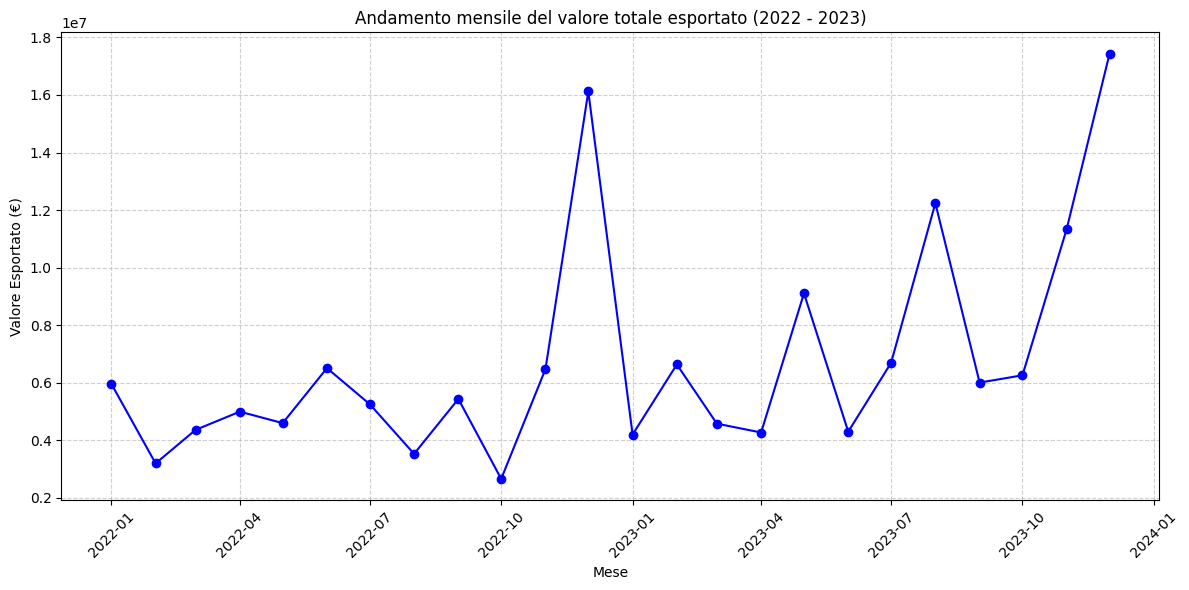

In [40]:
# Raggruppiamo per mese e sommiamo il valore totale esportato
andamento_temporale = ex.groupby('mese')['valore'].sum().reset_index()

# Creazione del grafico
plt.figure(figsize=(12, 6))
plt.plot(andamento_temporale['mese'], andamento_temporale['valore'], marker='o', color='b', linestyle='-')

# Personalizzazione del grafico
plt.title('Andamento mensile del valore totale esportato (2022 - 2023)')
plt.xlabel('Mese')
plt.ylabel('Valore Esportato (€)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()

# Visualizzazione
plt.show()

*Risposta:* Dicembre è il mese in cui si esporta di più

### 9. Un controllo di plausibilità

Calcola il prezzo medio implicito di ogni prodotto (valore totale diviso quantità totale). I prezzi hanno senso per quei prodotti?

In [41]:
# Calcoliamo valore totale e quantità totale per ciascun prodotto
analisi_prodotti = ex.groupby('prodotto').agg(
    valore_totale=('valore', 'sum'),
    quantita_totale=('quantita', 'sum')
).reset_index()

# Calcoliamo il prezzo medio implicito
analisi_prodotti['prezzo_medio'] = analisi_prodotti['valore_totale'] / analisi_prodotti['quantita_totale']

# Mostriamo i risultati
display(analisi_prodotti)

,prodotto,valore_totale,quantita_totale,prezzo_medio
0,Olio EVO 1L,38442930.0,46782,821.746184
1,Parmigiano 1kg,103324317.0,53709,1923.780316
2,Passata 700g,12045605.0,54110,222.613288
3,Pasta 500g,8348114.0,51387,162.455757


*Risposta:* no i prezzi sono sbilanciati rispetto al prodotto, probabili con l'attuale inflazione.

## Le tue decisioni

Scrivi la tabella delle decisioni di pulizia che hai preso (problema, decisione, verifica), come nel debrief della L3.

*Risposta:*
| Problema | Decisione | Verifica |
|---|---|---|
| duplicati | eliminati | corretto |
|denominazione paesi|unificata|corretto|
|conversione in euro|numerico|corretto|
|unificare date|date unificate|corretto|
|quantità negative|lasciate così perchè resi|corretto|